In [ ]:
import numpy as np
import os

import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as data
import torch.nn.functional as F
from torch.utils.data import DataLoader

import torchvision.transforms as transforms
import torchvision.utils as vutils
from torchvision.utils import save_image
from torchvision import datasets


# other  libraries...!!!
import numpy
from numpy import cov
from numpy import trace
from numpy import iscomplexobj
from numpy import asarray

from scipy.linalg import sqrtm

import matplotlib.pyplot as plt
from matplotlib.pyplot import imshow, imsave
%matplotlib inline
import argparse
from skimage.util import random_noise
from skimage.transform import resize

import cv2


In [ ]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
dataset = 'cifar'
#dataset = 'mnist'
BATCH_SIZE = 50

if dataset == 'mnist':
    transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5, ), (0.5,))])
    trainset = datasets.MNIST('../data',train=True, download=True, transform=transform)
    test = datasets.MNIST('../data',train=False, download=True, transform=transform)
elif dataset == 'fashionmnist':
    transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5, ), (0.5,))])
    trainset = datasets.FashionMNIST('../data',train=True, download=True, transform=transform)
    test = datasets.FashionMNIST('../data',train=False, download=True, transform=transform)
else:
    transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),])
    trainset = datasets.CIFAR10('../data',train=True, download=True, transform=transform)
    test = datasets.CIFAR10('../data',train=False, download=True, transform=transform)

train_dataloader = DataLoader(trainset, batch_size=BATCH_SIZE, shuffle=False)
test_dataloader = DataLoader(test, batch_size=BATCH_SIZE, shuffle=True)

  0%|          | 0/170498071 [00:00<?, ?it/s]

Extracting ../data/cifar-10-python.tar.gz to ../data
Files already downloaded and verified


In [ ]:
def save_noisy_image(img, name):
    if img.size(1) == 3:
        img = img.view(img.size(0), 3, 32, 32)
        save_image(img, name)
    else:
        img = img.view(img.size(0), 1, 28, 28)
        save_image(img, name)

# Escala un arreglo de imágenes a un tamaño dado
def scale_images(images, new_shape):
	images_list = list()
	for image in images:
		# Resize mediante interpolación de vecino más cercano
		new_image = resize(image, new_shape, 0)
		# Almacenar la nueva imagen
		images_list.append(new_image)
	return asarray(images_list)

def gaussian_noise(loader, mean=0, var=0.05, num_of_batches=10):
    list_of_batches = list()
    for i, data in enumerate(loader):
        img, _ = data[0], data[1]
        gauss_img = torch.tensor(random_noise(img, mode='gaussian', mean=mean, var=var, clip=True))
        if i==0:
          save_noisy_image(gauss_img[0:5], r"gaussian_{}_{}.png".format(mean,var))
        list_of_batches.append(gauss_img)
        if i+1 == num_of_batches: break
    return torch.cat(list_of_batches, dim=0)

def salt_paper_noise(loader, amount=0.05, num_of_batches=10):
    list_of_batches = list()
    for i, data in enumerate(loader):
        img, _ = data[0], data[1]
        salt_img = torch.tensor(random_noise(img, mode='salt', amount=amount))
        if i==0:
          save_noisy_image(salt_img[0:5], r"salt_{}.png".format(amount))
        list_of_batches.append(salt_img)
        if i+1 == num_of_batches: break
    return torch.cat(list_of_batches, dim=0)

def speckle_noise(loader, mean=0, var=0.05, num_of_batches=10):
    list_of_batches = list()
    for i, data in enumerate(loader):
        img, _ = data[0], data[1]
        speckle_img = torch.tensor(random_noise(img, mode='speckle', mean=mean, var=var, clip=True))
        if i==0:
          save_noisy_image(speckle_img[0:5], r"speckle_{}_{}.png".format(mean,var))
        list_of_batches.append(speckle_img)
        if i+1 == num_of_batches: break
    return torch.cat(list_of_batches, dim=0)

gaussian1 = gaussian_noise(train_dataloader, mean=0, var=0.01)
gaussian2 = gaussian_noise(train_dataloader, mean=0, var=0.05)
gaussian3 = gaussian_noise(train_dataloader, mean=0, var=0.10)

salt1 = salt_paper_noise(train_dataloader, amount=0.01)
salt2 = salt_paper_noise(train_dataloader, amount=0.05)
salt3 = salt_paper_noise(train_dataloader, amount=0.10)

speckle3 = speckle_noise(train_dataloader, mean=0, var=0.10)
speckle2 = speckle_noise(train_dataloader, mean=0, var=0.05)
speckle1 = speckle_noise(train_dataloader, mean=0, var=0.01)


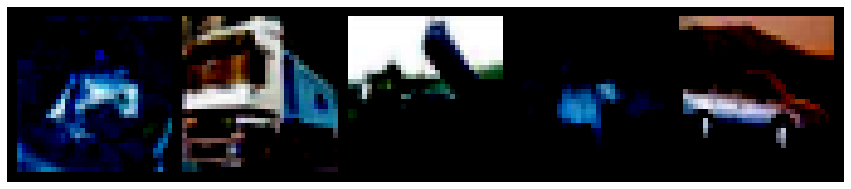

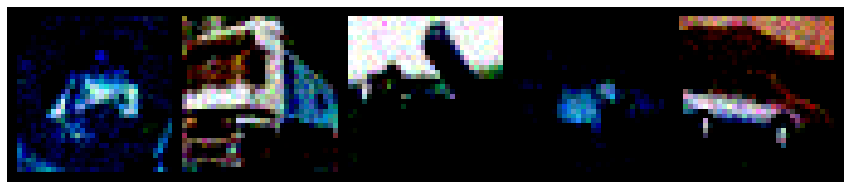

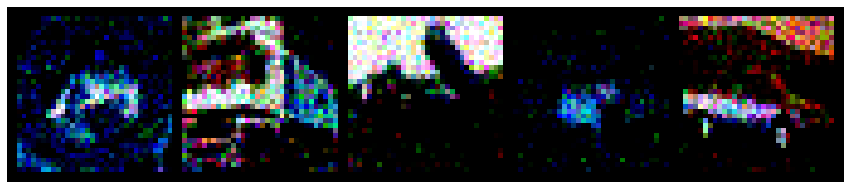

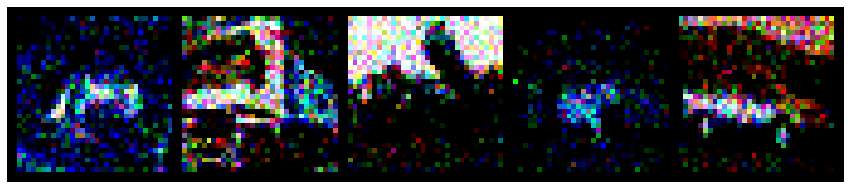

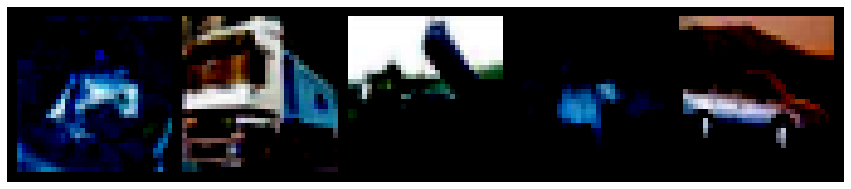

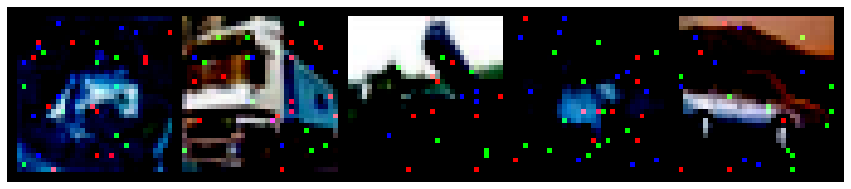

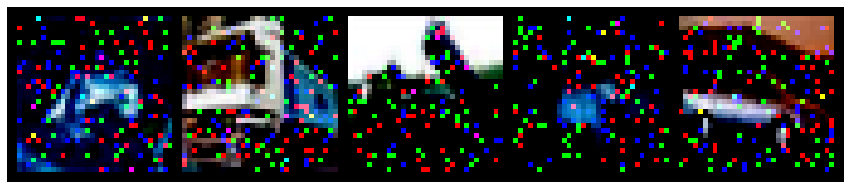

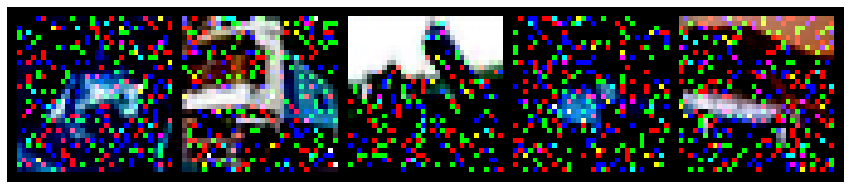

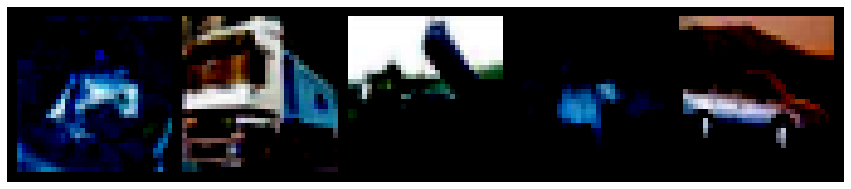

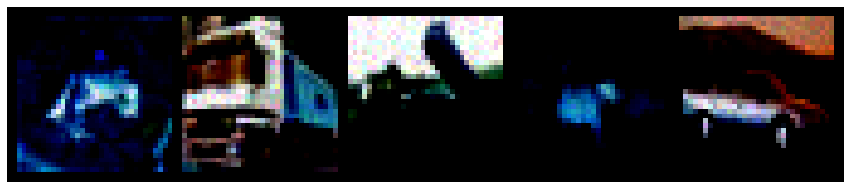

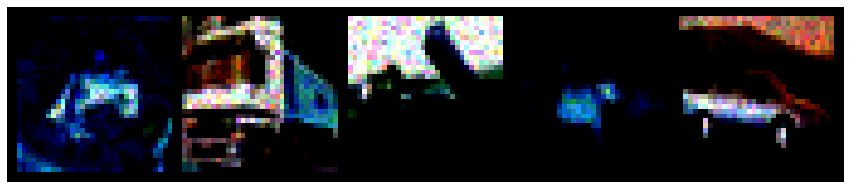

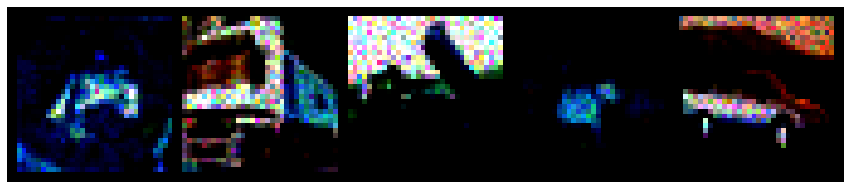

In [ ]:
for data in train_dataloader:
  img, _ = data[0], data[1]
  break
gauss_img = torch.tensor(random_noise(img[0:5], mode='gaussian', mean=0, var=0, clip=True))
save_noisy_image(gauss_img, r"original.png")

def show_actual_and_modified_images(noise_type='gaussian'):
  if noise_type != 'salt':
    mean = '_0'
  else:
    mean = ''
  image_name1 =  noise_type + mean + '_0.01.png'
  image_name2 =  noise_type + mean + '_0.05.png'
  image_name3 =  noise_type + mean + '_0.1.png'

  plt.figure(figsize=(15,15))
  plt.subplot(3,1,1)
  plt.imshow(cv2.imread(r"original.png"))
  plt.axis('off')

  plt.figure(figsize=(15,15))
  plt.subplot(3,1,1)
  plt.imshow(cv2.imread(image_name1))
  plt.axis('off')

  plt.figure(figsize=(15,15))
  plt.subplot(3,1,2)
  plt.imshow(cv2.imread(image_name2))
  plt.axis('off')

  plt.figure(figsize=(15,15))
  plt.subplot(3,1,3)
  plt.imshow(cv2.imread(image_name3))
  plt.axis('off')

  plt.show()

show_actual_and_modified_images('gaussian')
show_actual_and_modified_images('salt')
show_actual_and_modified_images('speckle')


## Obtenemos el inception model necesarion para extraer las características

In [ ]:
inception_model = torch.hub.load('pytorch/vision:v0.10.0', 'inception_v3', pretrained=True)
inception_model.eval()

Using cache found in /root/.cache/torch/hub/pytorch_vision_v0.10.0


Inception3(
  (Conv2d_1a_3x3): BasicConv2d(
    (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), bias=False)
    (bn): BatchNorm2d(32, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (Conv2d_2a_3x3): BasicConv2d(
    (conv): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(32, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (Conv2d_2b_3x3): BasicConv2d(
    (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn): BatchNorm2d(64, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (maxpool1): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  (Conv2d_3b_1x1): BasicConv2d(
    (conv): Conv2d(64, 80, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(80, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (Conv2d_4a_3x3): BasicConv2d(
    (conv): Conv2d(80, 192, kernel_size=(3, 3), stri

## Creamos una versión del modelo que nos retorne solo las características. Eliminamos la última capa

In [ ]:
from torchvision.models.feature_extraction import get_graph_node_names
from torchvision.models.feature_extraction import create_feature_extractor

# Extraemos todas los parámetros de entrenamiento y evaluación en forma de grafo
train_nodes, eval_nodes = get_graph_node_names(inception_model)

# Se quita la útlima capa lineal del modelo de inceptionV3 para quedarnos con la activación de las 2048 características
return_nodes = eval_nodes[:-1]

# Creamos el extractor de caractarísticas con las capas deseadas (todas menos la última)
feature_inception = create_feature_extractor(inception_model, return_nodes=return_nodes).to(DEVICE)

/usr/local/lib/python3.7/dist-packages/torchvision/models/feature_extraction.py:175: UserWarning: NOTE: The nodes obtained by tracing the model in eval mode are a subsequence of those obtained in train mode. When choosing nodes for feature extraction, you may need to specify output nodes for train and eval mode separately.
  warnings.warn(msg + suggestion_msg)


## Código necesario para obener las salidas de activación de la red dadas unas imágenes

In [ ]:
# Devuelve la salida de la última capa con las características dado un batch de imágenes
def get_activations_from_images(images, model):
  images = F.upsample(images, size=(299, 299), mode='bilinear').to(DEVICE)
  activations = model(images)['avgpool']
  del images
  torch.cuda.empty_cache()
  return activations

# Calcula la salida de la última capa con las características para todas las imágenes dado un data loader
def get_activations_from_data_loader(loader, model, BATCH_SIZE=BATCH_SIZE, n_batches=10):

  n_used_imgs = n_batches * BATCH_SIZE
  pred_arr = np.empty((n_used_imgs, 2048))

  print("Computing activations for {} images ({} batches).".format(n_used_imgs, n_batches))

  for i, data in enumerate(loader):
    start = i * BATCH_SIZE
    end = start + BATCH_SIZE

    img, _ = data[0], data[1]
    img = img.to(DEVICE)

    pred = get_activations_from_images(img, model)
    pred_arr[start:end] = pred.cpu().data.numpy().reshape(BATCH_SIZE, -1)
    print(" - Processed {} batches of {}.".format(i+1,n_batches))
    if i+1 == n_batches: break

  return pred_arr

# Calcula la salida de la última capa con las características para todas las imágenes dada una lista de imágenes
def get_activations_from_list_of_images(images, model, BATCH_SIZE=BATCH_SIZE, n_batches=10):
  d0 = len(images)
  if BATCH_SIZE > d0:
      BATCH_SIZE = d0

  n_batches = d0 // BATCH_SIZE
  n_used_imgs = n_batches * BATCH_SIZE

  pred_arr = np.empty((n_used_imgs, 2048))

  print("Computing activations for {} images ({} batches).".format(d0, n_batches))

  for i in range(n_batches):
    start = i * BATCH_SIZE
    end = start + BATCH_SIZE

    batch = images[start:end]
    batch = batch.to(DEVICE)

    pred = get_activations_from_images(batch, model)
    pred_arr[start:end] = pred.cpu().data.numpy().reshape(BATCH_SIZE, -1)
    print(" - Processed {} batches of {}.".format(i+1,n_batches))
    if i+1 == n_batches: break

  return pred_arr

## Cálculo del FID score en función de la activación de la última capa (características)

In [ ]:
def get_fid_score(act1, act2):
  mu1 = act1.mean(axis=0)
  sigma1 = cov(act1, rowvar=False)

  mu2 = act2.mean(axis=0)
  sigma2 = cov(act2, rowvar=False)

  # calcular la suma de las diferencias de las medias al cuadrado
  ssdiff = numpy.sum((mu1 - mu2)**2.0)
  # calcular la raíz cuadrada del producto de covarianzas
  covmean = sqrtm(sigma1.dot(sigma2))
  # tomar la parte real para los números complejos
  if iscomplexobj(covmean):
    covmean = covmean.real
  # calcular FID
  fid = ssdiff + trace(sigma1 + sigma2 - 2.0 * covmean)

  return fid

## Obtención de los resultados

In [ ]:
act1 = get_activations_from_data_loader(train_dataloader, feature_inception)

act_11 = get_activations_from_list_of_images(gaussian1.type(torch.cuda.FloatTensor), feature_inception)
act_12 = get_activations_from_list_of_images(gaussian2.type(torch.cuda.FloatTensor), feature_inception)
act_13 = get_activations_from_list_of_images(gaussian3.type(torch.cuda.FloatTensor), feature_inception)

act_21 = get_activations_from_list_of_images(salt1.type(torch.cuda.FloatTensor), feature_inception)
act_22 = get_activations_from_list_of_images(salt2.type(torch.cuda.FloatTensor), feature_inception)
act_23 = get_activations_from_list_of_images(salt3.type(torch.cuda.FloatTensor), feature_inception)

act_31 = get_activations_from_list_of_images(speckle1.type(torch.cuda.FloatTensor), feature_inception)
act_32 = get_activations_from_list_of_images(speckle2.type(torch.cuda.FloatTensor), feature_inception)
act_33 = get_activations_from_list_of_images(speckle3.type(torch.cuda.FloatTensor), feature_inception)




Computing activations for 500 images (10 batches).


/usr/local/lib/python3.7/dist-packages/torch/nn/functional.py:3722: UserWarning: nn.functional.upsample is deprecated. Use nn.functional.interpolate instead.
  warnings.warn("nn.functional.upsample is deprecated. Use nn.functional.interpolate instead.")


 - Processed 1 batches of 10.
 - Processed 2 batches of 10.
 - Processed 3 batches of 10.
 - Processed 4 batches of 10.
 - Processed 5 batches of 10.
 - Processed 6 batches of 10.
 - Processed 7 batches of 10.
 - Processed 8 batches of 10.
 - Processed 9 batches of 10.
 - Processed 10 batches of 10.
Computing activations for 500 images (10 batches).
 - Processed 1 batches of 10.
 - Processed 2 batches of 10.
 - Processed 3 batches of 10.
 - Processed 4 batches of 10.
 - Processed 5 batches of 10.
 - Processed 6 batches of 10.
 - Processed 7 batches of 10.
 - Processed 8 batches of 10.
 - Processed 9 batches of 10.
 - Processed 10 batches of 10.
Computing activations for 500 images (10 batches).
 - Processed 1 batches of 10.
 - Processed 2 batches of 10.
 - Processed 3 batches of 10.
 - Processed 4 batches of 10.
 - Processed 5 batches of 10.
 - Processed 6 batches of 10.
 - Processed 7 batches of 10.
 - Processed 8 batches of 10.
 - Processed 9 batches of 10.
 - Processed 10 batches of

FID score con las propias imágenes: 
-3.945258602848994e-05
FID score con las imágenes con ruido gaussiano: 


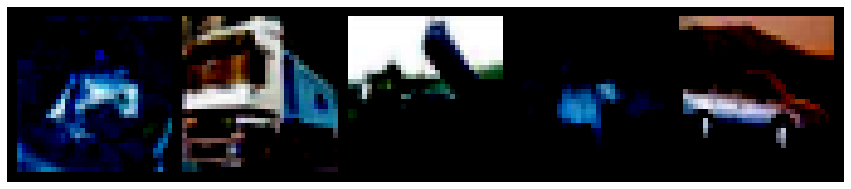

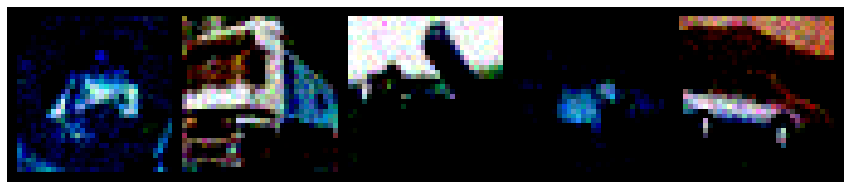

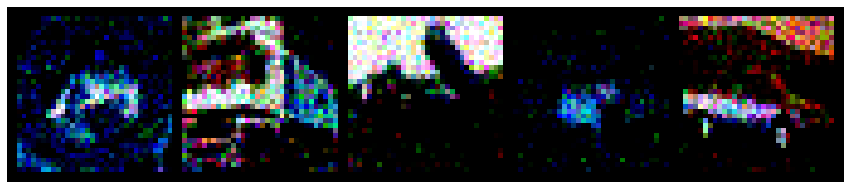

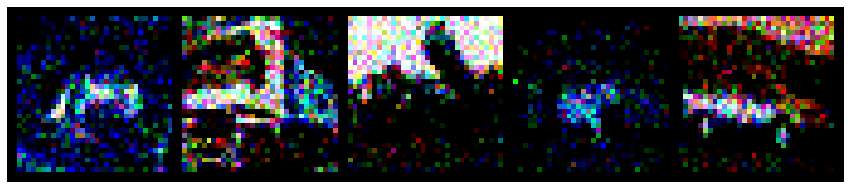

98.44377465599327
181.85707151409528
224.07304794941012
FID score con las imágenes con ruido sal y pimienta: 


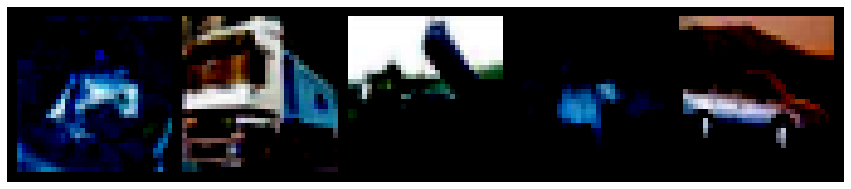

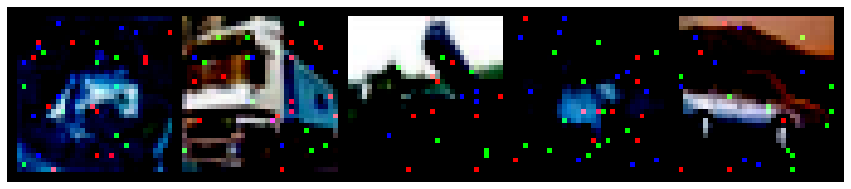

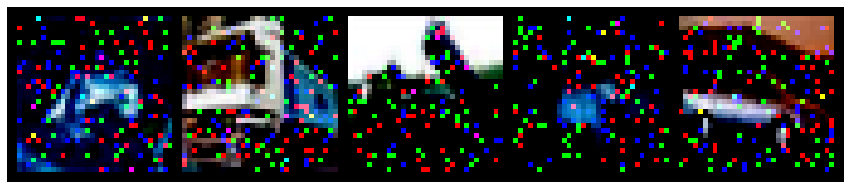

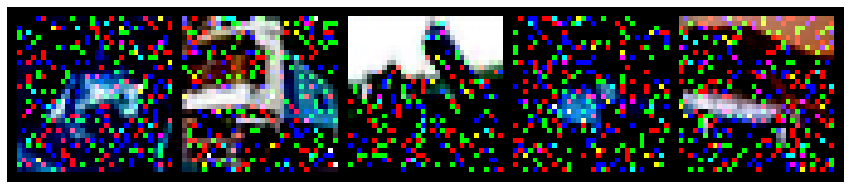

92.51499253992338
184.9418997931874
214.61323853379875
FID score con las imágenes con ruido punteado: 


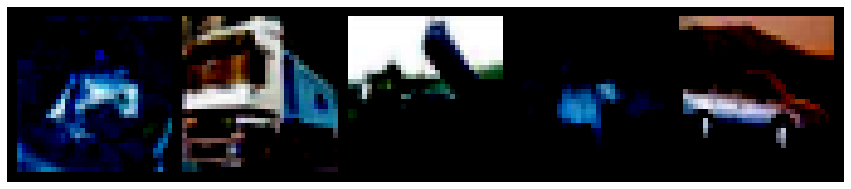

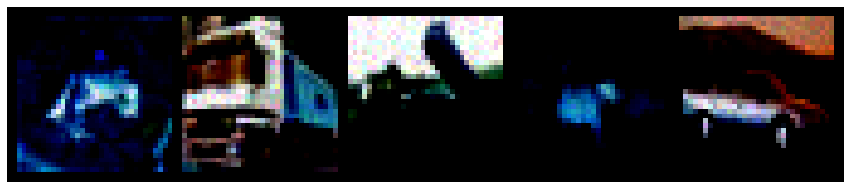

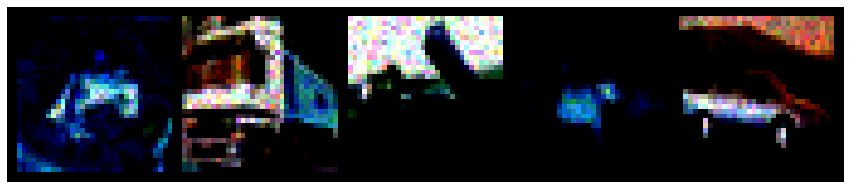

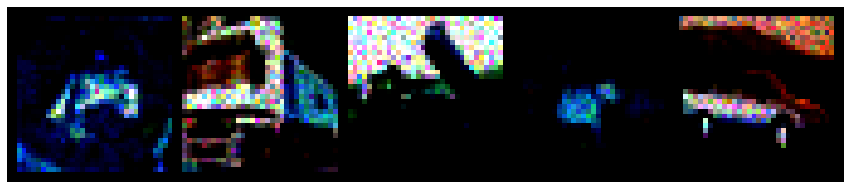

37.593717481301326
89.44835134804185
117.46180164445381


In [ ]:
print('FID score con las propias imágenes: ')
print(get_fid_score(act1,act1))

print('FID score con las imágenes con ruido gaussiano: ')
show_actual_and_modified_images('gaussian')
print(get_fid_score(act1,act_11))
print(get_fid_score(act1,act_12))
print(get_fid_score(act1,act_13))

print('FID score con las imágenes con ruido sal y pimienta: ')
show_actual_and_modified_images('salt')
print(get_fid_score(act1,act_21))
print(get_fid_score(act1,act_22))
print(get_fid_score(act1,act_23))

print('FID score con las imágenes con ruido punteado: ')
show_actual_and_modified_images('speckle')
print(get_fid_score(act1,act_31))
print(get_fid_score(act1,act_32))
print(get_fid_score(act1,act_33))